In [ ]:
# --- data paths (see README: data layout) ---
import os
from pathlib import Path

# Root of the data store. Override with the DATA_ROOT environment variable.
DATA_ROOT = os.environ.get(
    "DATA_ROOT",
    "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/AI-IFS-attributioncomparison/pnw2021",
)
# Root of this git repository (found by walking up from the working directory).
REPO = str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts").is_dir()))


In [4]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
from datetime import datetime, timedelta
import os
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D
import re
from pathlib import Path
from scipy.stats import ks_2samp
from scipy.stats import wasserstein_distance
from properscoring import crps_ensemble
from scipy.spatial.distance import cdist
from scipy.stats import gaussian_kde

In [5]:
# Helpers for datetime plots and loading in data
def combine_seed_ensembles(seed_paths):
    """
    Combine multiple GenCast seed files into a single ensemble
    along the 'sample' dimension.
    """
    datasets = []
    offset = 0

    for path in seed_paths:
        ds = xr.open_zarr(path)

        # remove trivial batch dimension
        if "batch" in ds.dims and ds.sizes["batch"] == 1:
            ds = ds.squeeze("batch")

        nmem = ds.sizes["sample"]

        # relabel members to avoid duplicates
        ds = ds.assign_coords(
            sample=np.arange(offset, offset + nmem)
        )

        datasets.append(ds)
        offset += nmem

    return xr.concat(datasets, dim="sample").sortby("sample")

def to_celsius(da):
    units = str(da.attrs.get("units", "")).lower()
    if units in ("k", "kelvin"):
        return da - 273.15
    return da

def lon_adjust(da, lat, lon):
    longitude_coords=da["longitude"]
    lon360 = float(longitude_coords.max()) > 180
    lon = lon % 360 if lon360 else lon
    return da.sel(latitude=lat, longitude=lon, method="nearest")

def closest_member(da, truth_val, time, ens_dim="number", label="ensemble"):
    da_t = da.sel(time=time, method="nearest").dropna(ens_dim)
    dist = np.abs(da_t - truth_val)
    idx = dist.argmin(dim=ens_dim)
    member = da_t.isel({ens_dim: int(idx.values)})

    print(
        f"{label}: closest = {float(member.values):.2f} °C, "
        f"truth = {float(truth_val):.2f} °C, "
        f"abs diff = {abs(float(member.values) - float(truth_val)):.2f} °C"
    )
    return member, dist

def coolest_member(da, time, ens_dim="number", label="ensemble"):
    da_t = da.sel(time=time, method="nearest").dropna(ens_dim)
    idx = da_t.argmin(dim=ens_dim)
    member = da_t.isel({ens_dim: int(idx.values)})

    print(f"{label}: coolest = {float(member.values):.2f} °C")
    return member

def crps_calculation(ensemble, truth):
    crps = 0.0
    ens_members = np.sort(ensemble[np.isfinite(ensemble)])
    if len(ens_members) == 0:
        crps=np.nan
    
    #Pseudo code: crps[i] = SUM((F(y_k)^2)*(dy) for all functions smaller than the obs[i] value) + SUM ((F(y)-1)^2 for all values bigger than obs[i] value)*dy)
    for k in range(len(ens_members) - 1):
            y_k = ens_members[k]
            y_k1 = ens_members[k + 1]
            dy = y_k1 - y_k

            F_k = (k + 1) / len(ens_members) #+1 corrects for counting from zero

            if y_k1 <= truth:
                # entire interval is below the observation
                crps += (F_k ** 2) * dy
            elif y_k >= truth:
                # entire interval is above the observation
                crps += ((F_k - 1) ** 2) * dy
            else:
                # the observation splits this interval
                crps += (F_k ** 2) * (truth - y_k)
                crps += ((F_k - 1) ** 2) * (y_k1 - truth)
    return crps

/tmp/user/28413/ipykernel_180411/138476893.py:27: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.concat(datasets, dim="sample").sortby("sample")


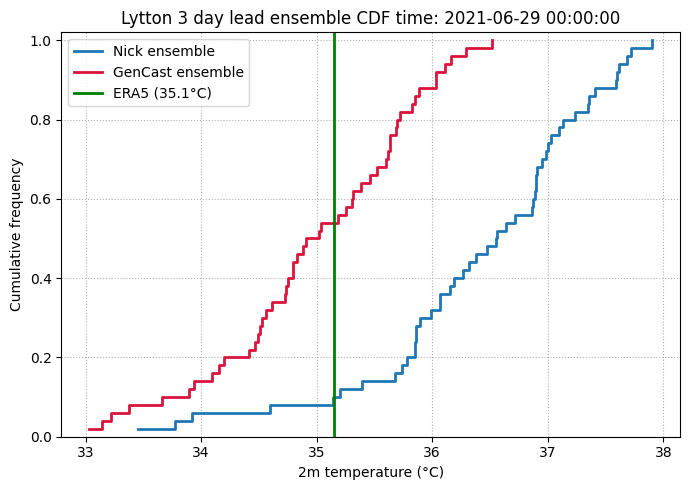

Nick: closest = 35.14 °C, truth = 35.15 °C, abs diff = 0.01 °C
GenCast: closest = 35.18 °C, truth = 35.15 °C, abs diff = 0.03 °C
Nick: coolest = 33.45 °C
GenCast: coolest = 33.03 °C
Nick CRPS: 0.8919050423322689
Gencast CRPS: 0.2292187186530427


In [6]:
gencast_init = pd.Timestamp("2021-06-26T00:00:00")
gencast_init_date = gencast_init.strftime("%Y-%m-%d")
nc_path = "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-26.nc"
lead3day_seed_paths = [
    (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-26T00_10d/pred_1deg_current_init-2021-06-26T00_10d_seed0_26ens.zarr"),
    (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-26T00_10d/pred_1deg_current_init-2021-06-26T00_10d_seed1_24ens.zarr"),
]
lead3day_50ens = combine_seed_ensembles(lead3day_seed_paths)
#gencast_path = f"predictions/init_{gencast_init_date}T00_30d_8ens_predictions.zarr"
era5 = xr.open_dataset(
    "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/era5/pnw025/sfc/2021.nc",
    engine="netcdf4"
)

# Open and preprocess
ds = xr.open_dataset(nc_path, engine="netcdf4")
ds = ds.rename({k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
                      if k in ds.coords or k in ds.dims})
t2m = to_celsius(ds["t2m"])

gencast = lead3day_50ens#xr.open_zarr(gencast_path)
if "batch" in gencast.dims:
    gencast = gencast.squeeze("batch")
gencast = gencast.rename({k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
                      if k in gencast.coords or k in gencast.dims})

# Same physical location for both datasets
city, city_lat, city_lon = "Lytton", 50.224444, -121.581944

# Extract city series from Nick/PNW025 and GenCast in the same way
city_da = lon_adjust(t2m, city_lat, city_lon)  # dims: time, number

# Anchor GenCast to the correct initialization time
gencast_da = to_celsius(gencast["2m_temperature"]).assign_coords(time=pd.to_datetime(gencast_init) + gencast["time"])
gencast_city = lon_adjust(gencast_da, city_lat, city_lon)

era5 = era5.rename({k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
                      if k in era5.coords or k in era5.dims})
era5_da = to_celsius(era5["t2m"])
era5_city = lon_adjust(era5_da, city_lat, city_lon)


# Pick one valid time
CDF_time = pd.to_datetime("2021-06-29T00:00:00")

# Select nearest available time and ensemble member values
nick_ens = city_da.sel(time=CDF_time, method="nearest").dropna("number").values.astype(float)
gencast_ens = gencast_city.sel(time=CDF_time, method="nearest").dropna("number").values.astype(float)

# Keep only finite values, and sort values
nick_x = np.sort(nick_ens[np.isfinite(nick_ens)])
gencast_x = np.sort(gencast_ens[np.isfinite(gencast_ens)])
era5_truth = float(
    era5_city.sel(time=CDF_time, method="nearest").values
)

nick_y = np.arange( 1, len(nick_x) + 1 ) / len(nick_x)
gencast_y = np.arange( 1, len(gencast_x) + 1) / len(gencast_x)

# Plot
plt.figure(figsize=(7, 5))

plt.step(nick_x, nick_y, where="post", linewidth=2, label="Nick ensemble")
plt.step(gencast_x, gencast_y, where="post", linewidth=2, color="crimson", label="GenCast ensemble")

plt.axvline(
    era5_truth,
    color="green",
    linewidth=2,
    label=f"ERA5 ({era5_truth:.1f}°C)"
)

plt.xlabel("2m temperature (°C)")
plt.ylabel("Cumulative frequency")
plt.title(f"{city} 3 day lead ensemble CDF time: {CDF_time}")
plt.ylim(0, 1.02)
plt.grid(True, linestyle=":")
plt.legend()
plt.tight_layout()
plt.show()

nick_closest, nick_dist = closest_member(city_da, era5_truth, CDF_time, ens_dim="number", label="Nick")
gencast_closest, gencast_dist = closest_member(gencast_city, era5_truth, CDF_time, ens_dim="number", label="GenCast")
nick_coolest = coolest_member(city_da, CDF_time, ens_dim="number", label="Nick")
gencast_coolest = coolest_member(gencast_city, CDF_time, ens_dim="number", label="GenCast")
nick_crps = crps_calculation(nick_x, era5_truth)
gencast_crps = crps_calculation(gencast_x, era5_truth)
print("Nick CRPS:", nick_crps)
print("Gencast CRPS:", gencast_crps)

In [7]:
def crps_map_pointwise(forecast_da, obs_da):
    """
    forecast_da is IFS/Gencast forecasted temp: (latitude, longitude, number)
    obs_da is the ground truth:      (latitude, longitude) 
    returns:     (latitude, longitude)
    """
    forecast_da = forecast_da.transpose("latitude", "longitude", "number")
    obs_da = obs_da.transpose("latitude", "longitude")
    
    forecast_lon = forecast_da["longitude"]
    if forecast_lon.max() > 180:
        forecast_da = forecast_da.assign_coords({"longitude": ((forecast_lon + 180) % 360) - 180})
    forecast_da = forecast_da.sortby("longitude").sortby("latitude")
    obs_lon = obs_da["longitude"]
    if obs_lon.max() > 180:
        obs_da = obs_da.assign_coords({"longitude": ((obs_lon + 180) % 360) - 180}).sortby("longitude")
    obs_da = obs_da.sortby("longitude").sortby("latitude")

    forecast_da = forecast_da.sel(latitude=slice(*LAT_RANGE), longitude=slice(*LON_RANGE))
    obs_da = obs_da.sel(latitude=slice(*LAT_RANGE), longitude=slice(*LON_RANGE))

    # Align on common lat/lon grid
    obs_da, forecast_da = xr.align(obs_da, forecast_da, join="inner")

    nlat = obs_da.sizes["latitude"]
    nlon = obs_da.sizes["longitude"]
    nmem = forecast_da.sizes["number"]

    fcst = forecast_da.values.reshape(nlat * nlon, nmem)
    obs = obs_da.values.reshape(nlat * nlon)

    crps = np.empty(nlat * nlon, dtype=float)

    for i in range(nlat * nlon): #basically looping over each lat/long gridcell
        #out[i] = crps_ensemble(obs[i], fcst[i])
        ens_members = np.sort(fcst[i,:][np.isfinite(fcst[i,:])])
        if len(ens_members) == 0:
            crps[i]=np.nan
            continue
        total = 0.0
    
        #Pseudo code: crps[i] = SUM((F(y_k)^2)*(dy) for all functions smaller than the obs[i] value) + SUM ((F(y)-1)^2 for all values bigger than obs[i] value)*dy)
        for k in range(len(ens_members) - 1):
            y_k = ens_members[k]
            y_k1 = ens_members[k + 1]
            dy = y_k1 - y_k

            F_k = (k + 1) / len(ens_members) #+1 corrects for counting from zero

            if y_k1 <= obs[i]:
                # entire interval is below the observation
                total += (F_k ** 2) * dy
            elif y_k >= obs[i]:
                # entire interval is above the observation
                total += ((F_k - 1) ** 2) * dy
            else:
                # the observation splits this interval
                total += (F_k ** 2) * (obs[i] - y_k)
                total += ((F_k - 1) ** 2) * (y_k1 - obs[i])
        crps[i] = total
    print(crps.max(),crps.min())

    return xr.DataArray(
        crps.reshape(nlat, nlon),
        coords=obs_da.coords,
        dims=obs_da.dims,
        name="crps",
    )

9.15706192396182 0.048763601080812444


/tmp/user/28413/ipykernel_180411/138476893.py:27: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.concat(datasets, dim="sample").sortby("sample")


5.1678690910339355 0.04644701050372051


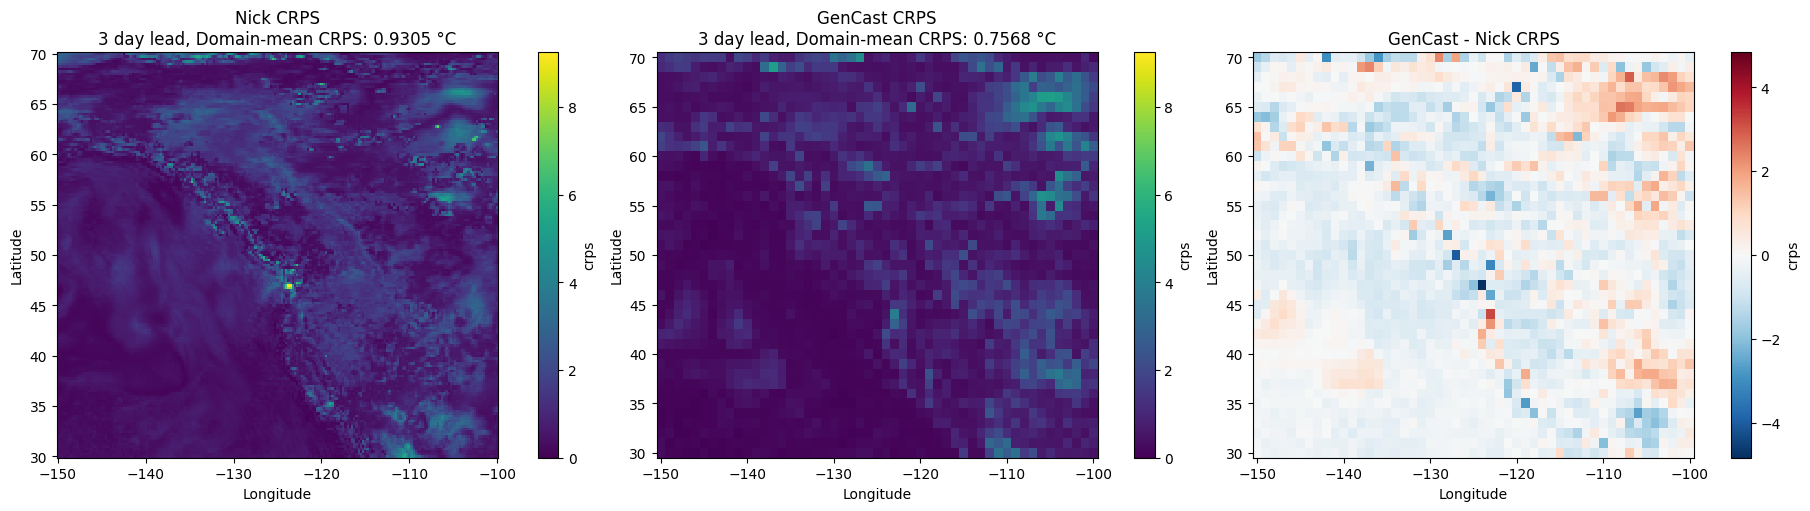

Domain-mean CRPS
Nick:    0.9305 °C
GenCast: 0.7568 °C


In [8]:
valid_time = pd.Timestamp("2021-06-29T00:00:00")
LAT_RANGE = (30, 70)
LON_RANGE = (-150, -100)

cases = [
    {
        "label": "3 day lead",
        "init_time": pd.Timestamp("2021-06-26T00:00:00"),
        "nc_path": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-26.nc",
        "seed_paths": [
            (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-26T00_10d/pred_1deg_current_init-2021-06-26T00_10d_seed0_26ens.zarr"),
            (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-26T00_10d/pred_1deg_current_init-2021-06-26T00_10d_seed1_24ens.zarr"),
        ],
    },
    {
        "label": "7 day lead",
        "init_time": pd.Timestamp("2021-06-22T00:00:00"),
        "nc_path": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-22.nc",
        "seed_paths": [
            (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-22T00_18d/pred_1deg_current_init-2021-06-22T00_18d_seed0_26ens.zarr"),
            (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-22T00_18d/pred_1deg_current_init-2021-06-22T00_18d_seed1_24ens.zarr"),
        ],
    },
    {
        "label": "11 day lead",
        "init_time": pd.Timestamp("2021-06-18T00:00:00"),
        "nc_path": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-18.nc",
        "seed_paths": [
            (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-18T00_26d/pred_1deg_current_init-2021-06-18T00_26d_seed0_26ens.zarr"),
            (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-18T00_26d/pred_1deg_current_init-2021-06-18T00_26d_seed1_24ens.zarr"),
        ],
    },
    {
        "label": "11 day lead",
        "init_time": pd.Timestamp("2021-06-18T00:00:00"),
        "nc_path": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-18.nc",
        "seed_paths": [
            (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-18T00_26d/pred_1deg_current_init-2021-06-18T00_26d_seed0_26ens.zarr"),
            (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-18T00_26d/pred_1deg_current_init-2021-06-18T00_26d_seed1_24ens.zarr"),
        ],
    },
]

case = cases[0]  # change the lead time

era5 = xr.open_dataset(
    "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/era5/pnw025/sfc/2021.nc",
    engine="netcdf4")
era5 = era5.rename({k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
                      if k in era5.coords or k in era5.dims})
era5_truth = to_celsius(era5["t2m"]).sel(time=valid_time, method="nearest")

nick_da = xr.open_dataset(case["nc_path"], engine="netcdf4")
nick_da = nick_da.rename({k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
                      if k in nick_da.coords or k in nick_da.dims})
nick_da = to_celsius(nick_da["t2m"])
nick_fcst = nick_da.sel(time=valid_time)
nick_crps = crps_map_pointwise(nick_fcst, era5_truth)

gencast_da = combine_seed_ensembles(case["seed_paths"])
gencast_da = gencast_da.rename({k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
                      if k in gencast_da.coords or k in gencast_da.dims})
gencast_da = gencast_da.assign_coords(time=pd.to_datetime(gencast_init) + gencast_da["time"])
gencast_fcst = gencast_da["2m_temperature"].sel(time=valid_time)
gencast_fcst = to_celsius(gencast_fcst)
gencast_crps = crps_map_pointwise(gencast_fcst, era5_truth)

vmax = 9.244239252245213#max(float(gencast_crps.max()), float(nick_crps.max()))

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)

nick_crps.plot(ax=axes[0], cmap="viridis", vmin=0, vmax=vmax, add_colorbar=True)
axes[0].set_title(f"Nick CRPS\n{case['label']}, Domain-mean CRPS: {float(nick_crps.mean()):.4f} °C")

gencast_crps.plot(ax=axes[1], cmap="viridis", vmin=0, vmax=vmax, add_colorbar=True)
axes[1].set_title(f"GenCast CRPS\n{case['label']}, Domain-mean CRPS: {float(gencast_crps.mean()):.4f} °C")

(gencast_crps - nick_crps).plot(ax=axes[2], cmap="RdBu_r", center=0, add_colorbar=True)
axes[2].set_title("GenCast - Nick CRPS")

for ax in axes:
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
#    ax.set_xlim(-123, -119)
#    ax.set_ylim(45,52)


plt.show()

print("Domain-mean CRPS")
print(f"Nick:    {float(nick_crps.mean()):.4f} °C")
print(f"GenCast: {float(gencast_crps.mean()):.4f} °C")

In [9]:
def get_minmax_crps_location(crps_da):
    flat = crps_da.stack(point=("latitude", "longitude"))
    idx_max = flat.argmax("point")
    idx_min = flat.argmin("point")
    lat_max = float(flat["latitude"].isel(point=idx_max))
    lon_max = float(flat["longitude"].isel(point=idx_max))
    lat_min = float(flat["latitude"].isel(point=idx_min))
    lon_min = float(flat["longitude"].isel(point=idx_min))
    max_val = float(flat.isel(point=idx_max))
    min_val = float(flat.isel(point=idx_min))
    return lat_max, lon_max, max_val, lat_min, lon_min, min_val

def plot_empirical_cdf(ax, samples, label):
    samples = np.asarray(samples).ravel()
    samples = samples[np.isfinite(samples)]
    x = np.sort(samples)
    y = np.arange(1, len(x) + 1) / len(x)
    ax.step(x, y, where="post", label=label)

# Find best/worst point for each model
nick_lat_max, nick_lon_max, nick_max_crps, nick_lat_min, nick_lon_min, nick_min_crps = get_minmax_crps_location(nick_crps)
gen_lat_max, gen_lon_max, gen_max_crps,gen_lat_min, gen_lon_min, gen_min_crps = get_minmax_crps_location(gencast_crps)

print(f"Nick max CRPS at   lat={nick_lat_max:.3f}, lon={nick_lon_max:.3f}, CRPS={nick_max_crps:.4f} °C")
print(f"GenCast max CRPS at lat={gen_lat_max:.3f}, lon={gen_lon_max:.3f}, CRPS={gen_max_crps:.4f} °C")
print(f"Nick min CRPS at   lat={nick_lat_min:.3f}, lon={nick_lon_min:.3f}, CRPS={nick_min_crps:.4f} °C")
print(f"GenCast min CRPS at lat={gen_lat_min:.3f}, lon={gen_lon_min:.3f}, CRPS={gen_min_crps:.4f} °C")


Nick max CRPS at   lat=47.000, lon=-123.750, CRPS=9.1571 °C
GenCast max CRPS at lat=66.000, lon=-105.000, CRPS=5.1679 °C
Nick min CRPS at   lat=34.000, lon=-121.500, CRPS=0.0488 °C
GenCast min CRPS at lat=32.000, lon=-148.000, CRPS=0.0464 °C


/tmp/user/28413/ipykernel_180411/138476893.py:27: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.concat(datasets, dim="sample").sortby("sample")


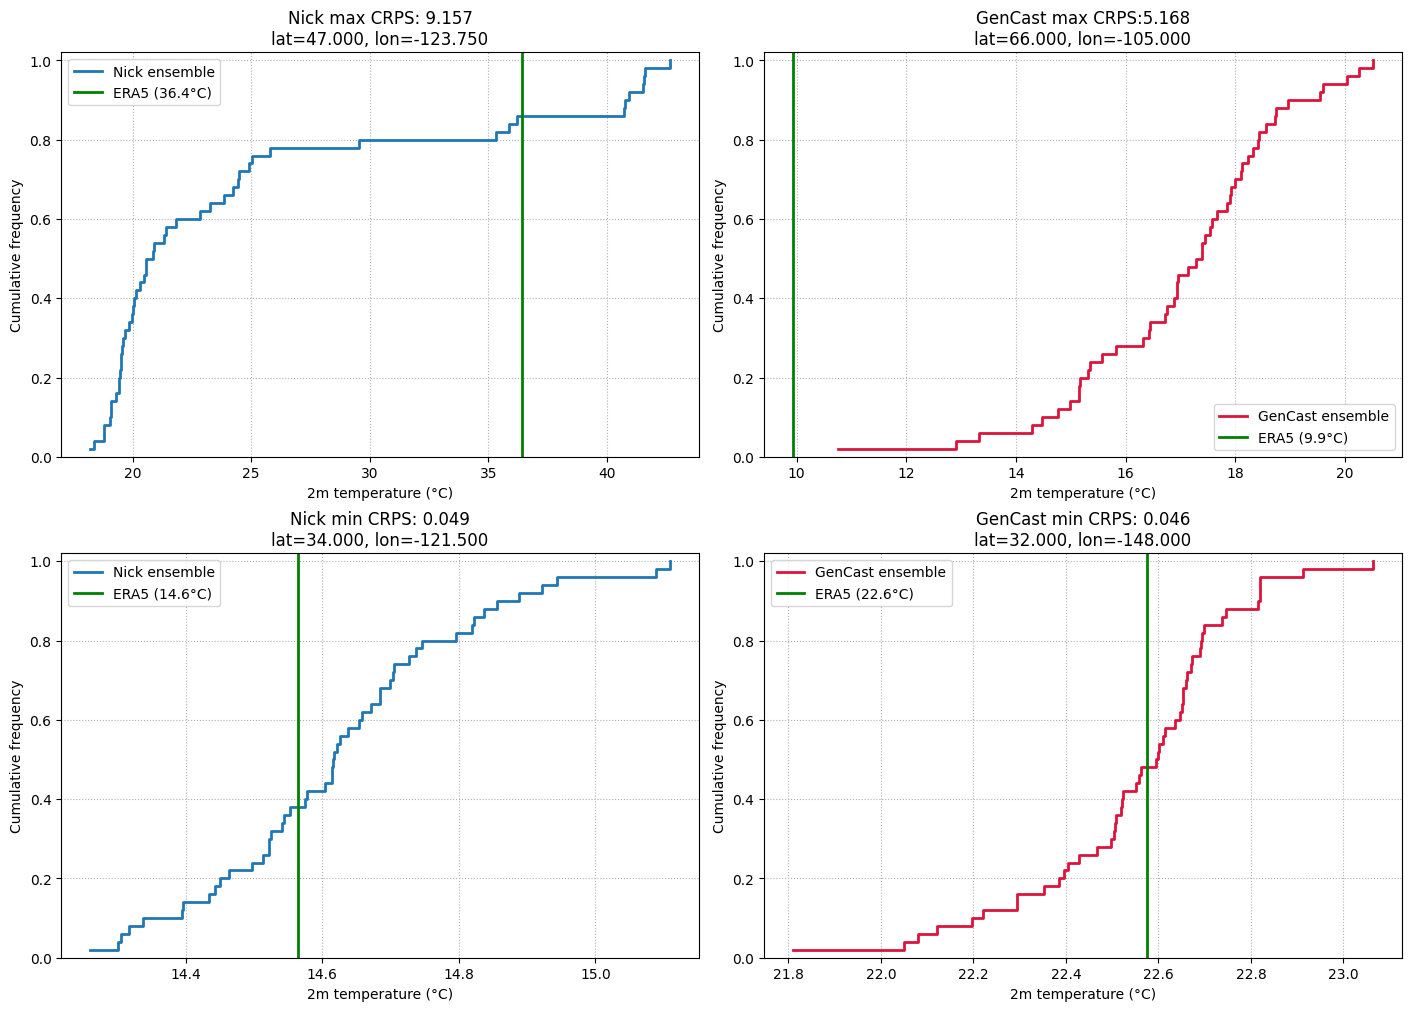

Nick max CRPS: 9.15706192396182
Nick min CRPS: 0.048763601080812444
GenCast max CRPS: 5.16787030029297
GenCast min CRPS: 0.04644701198221292


In [10]:
# CRPS locations
points = {
#    "Nick max":     (47.000, -123.750),
#    "Nick min":     (34.000, -121.500),
#    "GenCast max":  (66.000, -105.000),
#    "GenCast min":  (32.000, -148.000),
#}
    "Nick max":     (nick_lat_max, nick_lon_max),
    "Nick min":     (nick_lat_min, nick_lon_min),
    "GenCast max":  (gen_lat_max, gen_lon_max),
    "GenCast min":  (gen_lat_min, gen_lon_min),
}
CDF_time = pd.Timestamp("2021-06-29T00:00:00")

# Extract point series
nick_point_max = lon_adjust(t2m, *points["Nick max"])
nick_point_min = lon_adjust(t2m, *points["Nick min"])

gencast_da = combine_seed_ensembles(case["seed_paths"])
gencast_da = gencast_da.rename({k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
                      if k in gencast_da.coords or k in gencast_da.dims})
gencast_da = gencast_da.assign_coords(time=pd.to_datetime(gencast_init) + gencast_da["time"])
gencast_da = to_celsius(gencast_da["2m_temperature"])
gen_point_max = lon_adjust(gencast_da, *points["GenCast max"])
gen_point_min = lon_adjust(gencast_da, *points["GenCast min"])

era5_point_nick_max = lon_adjust(era5_da, *points["Nick max"])
era5_point_nick_min = lon_adjust(era5_da, *points["Nick min"])
era5_point_gen_max  = lon_adjust(era5_da, *points["GenCast max"])
era5_point_gen_min  = lon_adjust(era5_da, *points["GenCast min"])

# Ensemble members at the chosen valid time
nick_ens_max = nick_point_max.sel(time=CDF_time, method="nearest").dropna("number").values.astype(float)
nick_ens_min = nick_point_min.sel(time=CDF_time, method="nearest").dropna("number").values.astype(float)

gen_ens_max = gen_point_max.sel(time=CDF_time, method="nearest").dropna("number").values.astype(float)
gen_ens_min = gen_point_min.sel(time=CDF_time, method="nearest").dropna("number").values.astype(float)

# Truth at the same time
nick_truth_max = float(era5_point_nick_max.sel(time=CDF_time, method="nearest").values)
nick_truth_min = float(era5_point_nick_min.sel(time=CDF_time, method="nearest").values)
gen_truth_max  = float(era5_point_gen_max.sel(time=CDF_time, method="nearest").values)
gen_truth_min  = float(era5_point_gen_min.sel(time=CDF_time, method="nearest").values)

# Clean / sort
nick_x_max = np.sort(nick_ens_max[np.isfinite(nick_ens_max)])
nick_x_min = np.sort(nick_ens_min[np.isfinite(nick_ens_min)])
gen_x_max  = np.sort(gen_ens_max[np.isfinite(gen_ens_max)])
gen_x_min  = np.sort(gen_ens_min[np.isfinite(gen_ens_min)])

nick_y_max = np.arange(1, len(nick_x_max) + 1) / len(nick_x_max)
nick_y_min = np.arange(1, len(nick_x_min) + 1) / len(nick_x_min)
gen_y_max  = np.arange(1, len(gen_x_max) + 1) / len(gen_x_max)
gen_y_min  = np.arange(1, len(gen_x_min) + 1) / len(gen_x_min)

# Plot
fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)

# Nick max
axes[0, 0].step(nick_x_max, nick_y_max, where="post", linewidth=2, label="Nick ensemble")
axes[0, 0].axvline(nick_truth_max, color="green", linewidth=2, label=f"ERA5 ({nick_truth_max:.1f}°C)")
axes[0, 0].set_title(f"Nick max CRPS: {crps_calculation(nick_x_max, nick_truth_max):.3f}\nlat=47.000, lon=-123.750")
axes[0, 0].set_xlabel("2m temperature (°C)")
axes[0, 0].set_ylabel("Cumulative frequency")
axes[0, 0].set_ylim(0, 1.02)
axes[0, 0].grid(True, linestyle=":")
axes[0, 0].legend()

# Nick min
axes[1, 0].step(nick_x_min, nick_y_min, where="post", linewidth=2, label="Nick ensemble")
axes[1, 0].axvline(nick_truth_min, color="green", linewidth=2, label=f"ERA5 ({nick_truth_min:.1f}°C)")
axes[1, 0].set_title(f"Nick min CRPS: {crps_calculation(nick_x_min, nick_truth_min):.3f}\nlat=34.000, lon=-121.500")
axes[1, 0].set_xlabel("2m temperature (°C)")
axes[1, 0].set_ylabel("Cumulative frequency")
axes[1, 0].set_ylim(0, 1.02)
axes[1, 0].grid(True, linestyle=":")
axes[1, 0].legend()

# GenCast max
axes[0, 1].step(gen_x_max, gen_y_max, where="post", linewidth=2, color="crimson", label="GenCast ensemble")
axes[0, 1].axvline(gen_truth_max, color="green", linewidth=2, label=f"ERA5 ({gen_truth_max:.1f}°C)")
axes[0, 1].set_title(f"GenCast max CRPS:{crps_calculation(gen_x_max, gen_truth_max):.3f}\nlat=66.000, lon=-105.000")
axes[0, 1].set_xlabel("2m temperature (°C)")
axes[0, 1].set_ylabel("Cumulative frequency")
axes[0, 1].set_ylim(0, 1.02)
axes[0, 1].grid(True, linestyle=":")
axes[0, 1].legend()

# GenCast min
axes[1, 1].step(gen_x_min, gen_y_min, where="post", linewidth=2, color="crimson", label="GenCast ensemble")
axes[1, 1].axvline(gen_truth_min, color="green", linewidth=2, label=f"ERA5 ({gen_truth_min:.1f}°C)")
axes[1, 1].set_title(f"GenCast min CRPS: {crps_calculation(gen_x_min, gen_truth_min):.3f}\nlat=32.000, lon=-148.000")
axes[1, 1].set_xlabel("2m temperature (°C)")
axes[1, 1].set_ylabel("Cumulative frequency")
axes[1, 1].set_ylim(0, 1.02)
axes[1, 1].grid(True, linestyle=":")
axes[1, 1].legend()

plt.show()

# CRPS values from the same exact ensemble samples
print("Nick max CRPS:", crps_calculation(nick_x_max, nick_truth_max))
print("Nick min CRPS:", crps_calculation(nick_x_min, nick_truth_min))
print("GenCast max CRPS:", crps_calculation(gen_x_max, gen_truth_max))
print("GenCast min CRPS:", crps_calculation(gen_x_min, gen_truth_min))

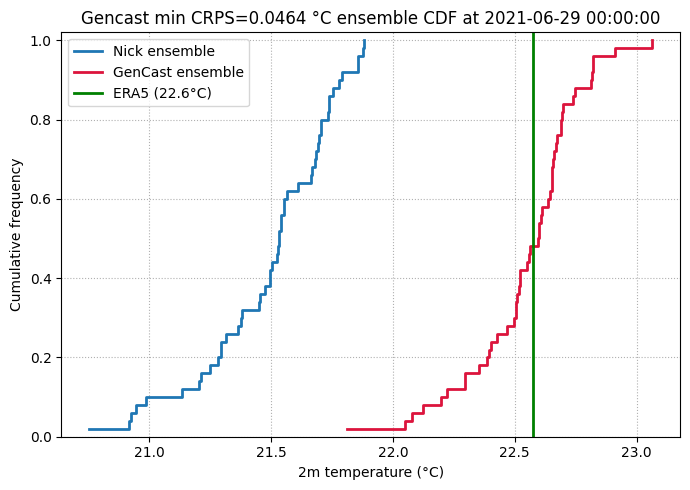

Nick CRPS: 0.24408881471216912
GenCast CRPS: 0.04644701198221292


In [11]:
# Pick the location you want
#city, city_lat, city_lon = "Lytton", 50.224444, -121.581944
city, city_lat, city_lon = "Gencast min CRPS=0.0464 °C", 32, -148
CDF_time = pd.Timestamp("2021-06-29T00:00:00")
#GenCast min CRPS at lat=32.000, lon=-148.000, CRPS=0.0464 °C

# Point series for each model
nick_point = lon_adjust(t2m, city_lat, city_lon)          # dims: time, number
gen_point  = lon_adjust(gencast_da, city_lat, city_lon)   # dims: time, number
era5_point  = lon_adjust(era5_da, city_lat, city_lon)     # dims: time

# Ensemble members at the chosen valid time
nick_ens = nick_point.sel(time=CDF_time, method="nearest").dropna("number").values.astype(float)
gen_ens  = gen_point.sel(time=CDF_time, method="nearest").dropna("number").values.astype(float)

# Truth at the same time
era5_truth = float(era5_point.sel(time=CDF_time, method="nearest").values)

# Clean / sort
nick_x = np.sort(nick_ens[np.isfinite(nick_ens)])
gen_x  = np.sort(gen_ens[np.isfinite(gen_ens)])

nick_y = np.arange(1, len(nick_x) + 1) / len(nick_x)
gen_y  = np.arange(1, len(gen_x) + 1) / len(gen_x)

# Plot the ensemble CDFs
plt.figure(figsize=(7, 5))
plt.step(nick_x, nick_y, where="post", linewidth=2, label="Nick ensemble")
plt.step(gen_x, gen_y, where="post", linewidth=2, color="crimson", label="GenCast ensemble")
plt.axvline(era5_truth, color="green", linewidth=2, label=f"ERA5 ({era5_truth:.1f}°C)")
plt.xlabel("2m temperature (°C)")
plt.ylabel("Cumulative frequency")
plt.title(f"{city} ensemble CDF at {CDF_time}")
plt.ylim(0, 1.02)
plt.grid(True, linestyle=":")
plt.legend()
plt.tight_layout()
plt.show()

# CRPS from the same exact ensemble samples
nick_crps = crps_calculation(nick_x, era5_truth)
gen_crps  = crps_calculation(gen_x, era5_truth)

print("Nick CRPS:", nick_crps)
print("GenCast CRPS:", gen_crps)

In [12]:
# Perfect deterministic forecast
ensemble = np.array([5.0])
truth = 5.0
print(crps_calculation(ensemble, truth))

# Order invariance
e1 = np.array([1,2,3,4])
e2 = np.array([4,2,1,3])

c1 = crps_calculation(e1, 2.5)
c2 = crps_calculation(e2, 2.5)

print(c1, c2)

assert np.isclose(c1, c2)

# Translation
ensemble = np.array([1,2,4])
truth = 3

c1 = crps_calculation(ensemble, truth)
c2 = crps_calculation(ensemble + 100, truth + 100)

print(c1, c2)

assert np.isclose(c1, c2)

0.0
0.375 0.375
0.6666666666666667 0.6666666666666667



From Gneiting2007, 

$$
\mathrm{CRPS}\!\left(\mathcal{N}(\mu,\sigma^2), x\right)
=
\sigma
\left[
\frac{1}{\sqrt{\pi}}
- 2\phi(z)
- z\left(2\Phi(z)-1\right)
\right],
\qquad
z=\frac{x-\mu}{\sigma}.
$$

In [13]:
import numpy as np
from scipy.stats import norm

mu = 5.0
sigma = 2.0
truth = 6.3
rng = np.random.default_rng(0)

z = (truth - mu) / sigma
crps_exact = sigma * (
    + 1 / np.sqrt(np.pi)
    - 2 * norm.pdf(z)
    - z * (2 * norm.cdf(z) - 1)
)

print("Analytical:", crps_exact)

for n in [10, 50, 100, 500, 1000, 10000]:
    vals = []
    for _ in range(200):
        ensemble = rng.normal(mu, sigma, size=n)
        vals.append(crps_calculation(ensemble, truth))
    vals = np.array(vals)
    print(f"{n:6d}  mean={vals.mean():.6f}  std={vals.std():.6f}")

Analytical: -0.7931103834808966
    10  mean=0.909209  std=0.340322
    50  mean=0.802762  std=0.157802
   100  mean=0.803325  std=0.108511
   500  mean=0.794283  std=0.048984
  1000  mean=0.791887  std=0.034966
 10000  mean=0.792894  std=0.011072


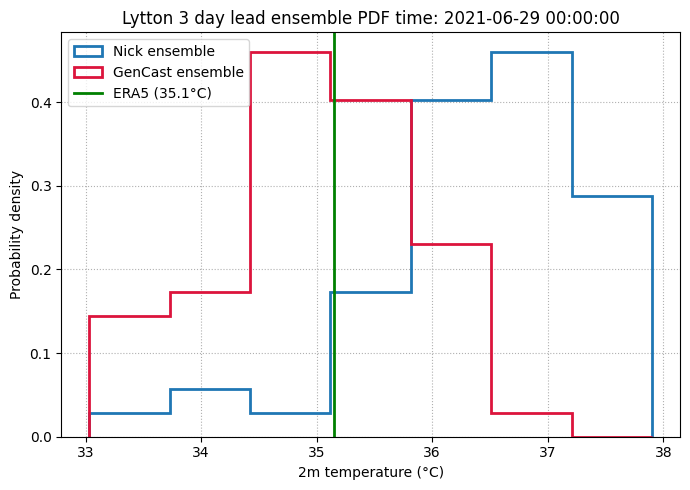

Nick CRPS: 0.8919050423322689
Gencast CRPS: 0.2292187186530427


In [14]:
#PDF instead of CDF, using histograms
CDF_time = pd.to_datetime("2021-06-29T00:00:00")
city, city_lat, city_lon = "Lytton", 50.224444, -121.581944

# Select nearest available time and ensemble member values
nick_ens = city_da.sel(time=CDF_time, method="nearest").dropna("number").values.astype(float)
gencast_ens = gencast_city.sel(time=CDF_time, method="nearest").dropna("number").values.astype(float)

# Keep only finite values
nick_x = np.sort(nick_ens[np.isfinite(nick_ens)])
gencast_x = np.sort(gencast_ens[np.isfinite(gencast_ens)])

era5_truth = float(
    era5_city.sel(time=CDF_time, method="nearest").values
)

# Use common bin edges for a fair comparison
all_vals = np.concatenate([nick_x, gencast_x])
bin_edges = np.histogram_bin_edges(all_vals, bins="fd")  # or bins="fd", 15, 20, etc.

# Plot histogram PDF
plt.figure(figsize=(7, 5))

plt.hist(
    nick_x,
    bins=bin_edges,
    density=True,
    histtype="step",
    linewidth=2,
    label="Nick ensemble",
)

plt.hist(
    gencast_x,
    bins=bin_edges,
    density=True,
    histtype="step",
    linewidth=2,
    color="crimson",
    label="GenCast ensemble",
)

plt.axvline(
    era5_truth,
    color="green",
    linewidth=2,
    label=f"ERA5 ({era5_truth:.1f}°C)"
)

plt.xlabel("2m temperature (°C)")
plt.ylabel("Probability density")
plt.title(f"{city} 3 day lead ensemble PDF time: {CDF_time}")
plt.grid(True, linestyle=":")
plt.legend()
plt.tight_layout()
plt.show()

nick_crps = crps_calculation(nick_x, era5_truth)
gencast_crps = crps_calculation(gencast_x, era5_truth)

print("Nick CRPS:", nick_crps)
print("Gencast CRPS:", gencast_crps)

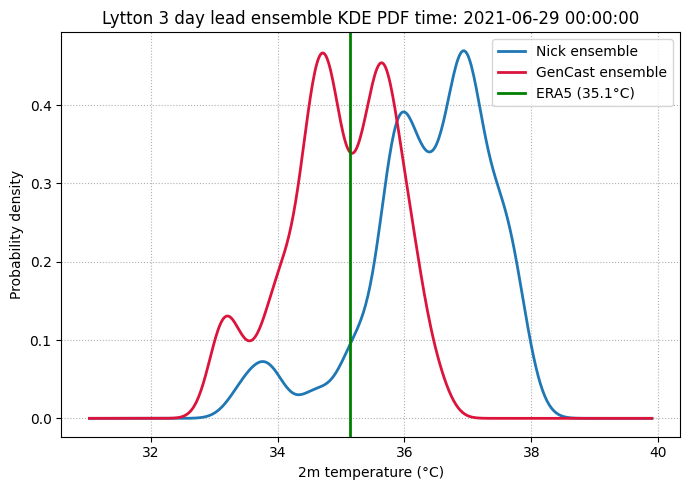

Nick CRPS: 0.8919050423322689
Gencast CRPS: 0.2292187186530427


In [15]:
# PDF instead of CDF, using KDE
CDF_time = pd.to_datetime("2021-06-29T00:00:00")

# Select nearest available time and ensemble member values
nick_ens = city_da.sel(time=CDF_time, method="nearest").dropna("number").values.astype(float)
gencast_ens = gencast_city.sel(time=CDF_time, method="nearest").dropna("number").values.astype(float)

# Keep only finite values
nick_x = nick_ens[np.isfinite(nick_ens)]
gencast_x = gencast_ens[np.isfinite(gencast_ens)]

era5_truth = float(
    era5_city.sel(time=CDF_time, method="nearest").values
)

# Sort for diagnostics if needed
nick_x_sorted = np.sort(nick_x)
gencast_x_sorted = np.sort(gencast_x)

# Build KDEs
nick_kde = gaussian_kde(nick_x, 0.25)
gencast_kde = gaussian_kde(gencast_x, 0.25)

# Common x-grid for plotting
all_vals = np.concatenate([nick_x, gencast_x, [era5_truth]])
x_min = all_vals.min() - 2.0
x_max = all_vals.max() + 2.0
x_grid = np.linspace(x_min, x_max, 500)

# Evaluate densities
nick_pdf = nick_kde(x_grid)
gencast_pdf = gencast_kde(x_grid)

# Plot KDE PDFs
plt.figure(figsize=(7, 5))

plt.plot(x_grid, nick_pdf, linewidth=2, label="Nick ensemble")
plt.plot(x_grid, gencast_pdf, linewidth=2, color="crimson", label="GenCast ensemble")

plt.axvline(
    era5_truth,
    color="green",
    linewidth=2,
    label=f"ERA5 ({era5_truth:.1f}°C)"
)

plt.xlabel("2m temperature (°C)")
plt.ylabel("Probability density")
plt.title(f"{city} 3 day lead ensemble KDE PDF time: {CDF_time}")
plt.grid(True, linestyle=":")
plt.legend()
plt.tight_layout()
plt.show()

# Diagnostics
nick_crps = crps_calculation(nick_x_sorted, era5_truth)
gencast_crps = crps_calculation(gencast_x_sorted, era5_truth)

print("Nick CRPS:", nick_crps)
print("Gencast CRPS:", gencast_crps)

/tmp/user/28413/ipykernel_180411/138476893.py:27: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.concat(datasets, dim="sample").sortby("sample")
/tmp/user/28413/ipykernel_180411/138476893.py:27: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.concat(datasets, dim="sample").sortby("sample")
/tmp

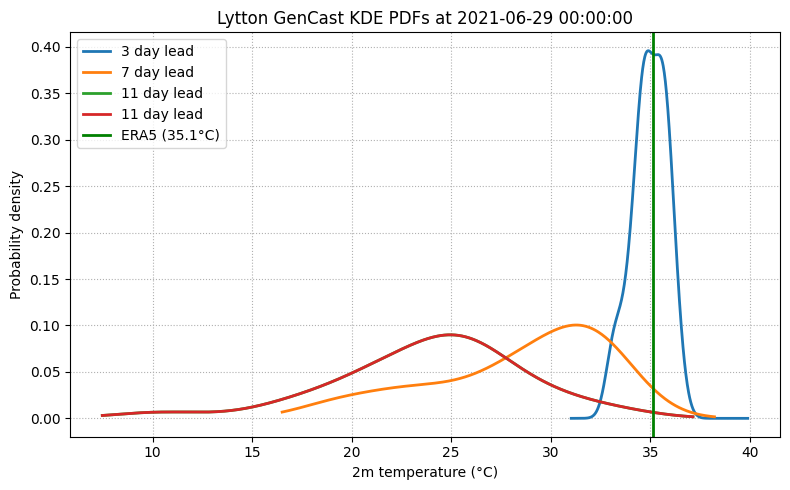

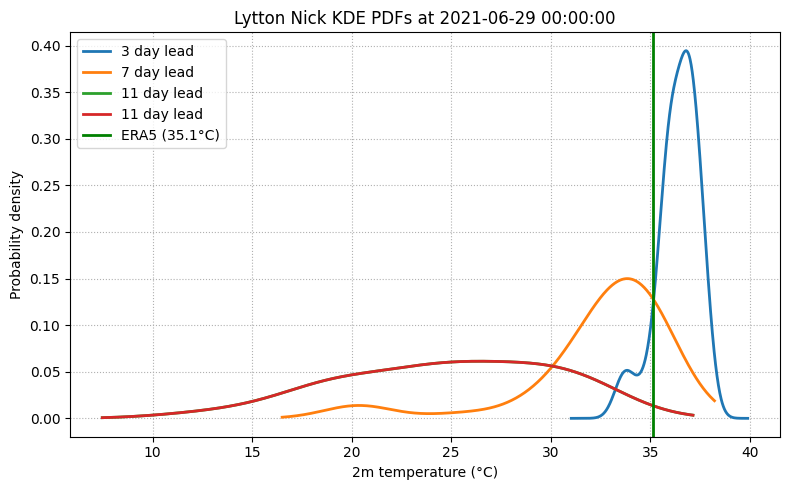

3 day lead
Nick CRPS: 0.8919050423322689
Gencast CRPS: 0.2292187186530427

7 day lead
Nick CRPS: 1.11142073709226
Gencast CRPS: 3.199780993652344

11 day lead
Nick CRPS: 5.280913531577152
Gencast CRPS: 6.968460803222657

11 day lead
Nick CRPS: 5.280913531577152
Gencast CRPS: 6.968460803222657



In [16]:
# PDFs for 3, 7, 11 day leads
# assumes these already exist in your notebook:
# valid_time, city, city_lat, city_lon, cases
# era5, to_celsius, lon_adjust, combine_seed_ensembles, crps_calculation

era5 = xr.open_dataset(
    "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/era5/pnw025/sfc/2021.nc",
    engine="netcdf4"
)
era5 = era5.rename({
    k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
    if k in era5.coords or k in era5.dims
})
era5_truth = to_celsius(era5["t2m"]).sel(time=valid_time, method="nearest")
era5_point = float(np.asarray(lon_adjust(era5_truth, city_lat, city_lon)).squeeze())

results = []

for case in cases:
    # Nick / PNW025
    nick_da = xr.open_dataset(case["nc_path"], engine="netcdf4")
    nick_da = nick_da.rename({
        k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
        if k in nick_da.coords or k in nick_da.dims
    })
    nick_da = to_celsius(nick_da["t2m"])
    nick_city = lon_adjust(nick_da, city_lat, city_lon)

    # GenCast
    gencast_da = combine_seed_ensembles(case["seed_paths"])
    gencast_da = gencast_da.rename({
        k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
        if k in gencast_da.coords or k in gencast_da.dims
    })
    gencast_da = gencast_da.assign_coords(time=pd.to_datetime(case["init_time"]) + gencast_da["time"])
    gencast_da = to_celsius(gencast_da["2m_temperature"])
    gencast_city = lon_adjust(gencast_da, city_lat, city_lon)

    # Extract ensemble values at the valid time
    nick_x = nick_city.sel(time=valid_time, method="nearest").dropna("number").values.astype(float)
    gencast_x = gencast_city.sel(time=valid_time, method="nearest").dropna("number").values.astype(float)

    nick_x = nick_x[np.isfinite(nick_x)]
    gencast_x = gencast_x[np.isfinite(gencast_x)]

    # Sort for CRPS
    nick_x_sorted = np.sort(nick_x)
    gencast_x_sorted = np.sort(gencast_x)

    # KDEs
    nick_kde = gaussian_kde(nick_x)
    gencast_kde = gaussian_kde(gencast_x)

    # Common x-grid for this lead
    all_vals = np.concatenate([nick_x, gencast_x, np.array([era5_point])])
    x_grid = np.linspace(all_vals.min() - 2.0, all_vals.max() + 2.0, 500)

    nick_pdf = nick_kde(x_grid)
    gencast_pdf = gencast_kde(x_grid)

    # CRPS diagnostics
    nick_crps = crps_calculation(nick_x_sorted, era5_point)
    gencast_crps = crps_calculation(gencast_x_sorted, era5_point)

    results.append({
        "label": case["label"],
        "x_grid": x_grid,
        "nick_pdf": nick_pdf,
        "gencast_pdf": gencast_pdf,
        "nick_crps": nick_crps,
        "gencast_crps": gencast_crps,
    })

# Plot GenCast: all three lead times
plt.figure(figsize=(8, 5))
for r in results:
    plt.plot(r["x_grid"], r["gencast_pdf"], linewidth=2, label=r["label"])
plt.axvline(era5_point, color="green", linewidth=2, label=f"ERA5 ({era5_point:.1f}°C)")
plt.xlabel("2m temperature (°C)")
plt.ylabel("Probability density")
plt.title(f"{city} GenCast KDE PDFs at {valid_time}")
plt.grid(True, linestyle=":")
plt.legend()
plt.tight_layout()
plt.show()

# Plot Nick: all three lead times
plt.figure(figsize=(8, 5))
for r in results:
    plt.plot(r["x_grid"], r["nick_pdf"], linewidth=2, label=r["label"])
plt.axvline(era5_point, color="green", linewidth=2, label=f"ERA5 ({era5_point:.1f}°C)")
plt.xlabel("2m temperature (°C)")
plt.ylabel("Probability density")
plt.title(f"{city} Nick KDE PDFs at {valid_time}")
plt.grid(True, linestyle=":")
plt.legend()
plt.tight_layout()
plt.show()

# Print CRPS diagnostics
for r in results:
    print(r["label"])
    print("Nick CRPS:", r["nick_crps"])
    print("Gencast CRPS:", r["gencast_crps"])
    print()

/tmp/user/28413/ipykernel_180411/138476893.py:27: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.concat(datasets, dim="sample").sortby("sample")
/tmp/user/28413/ipykernel_180411/138476893.py:27: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.concat(datasets, dim="sample").sortby("sample")
/tmp

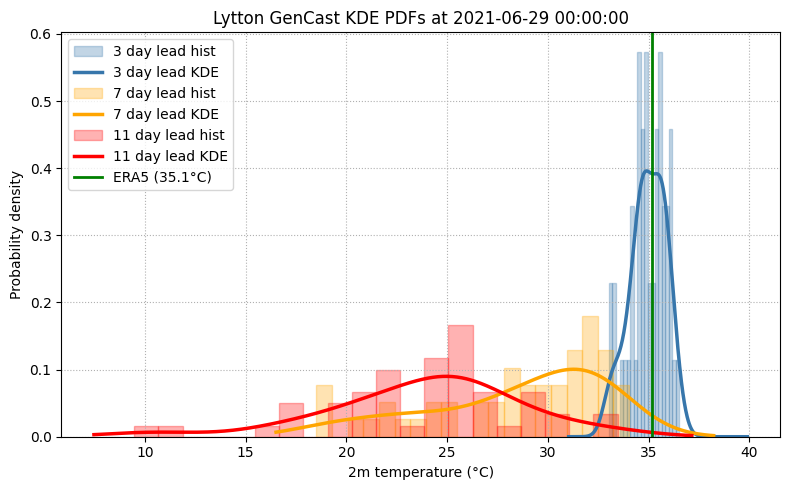

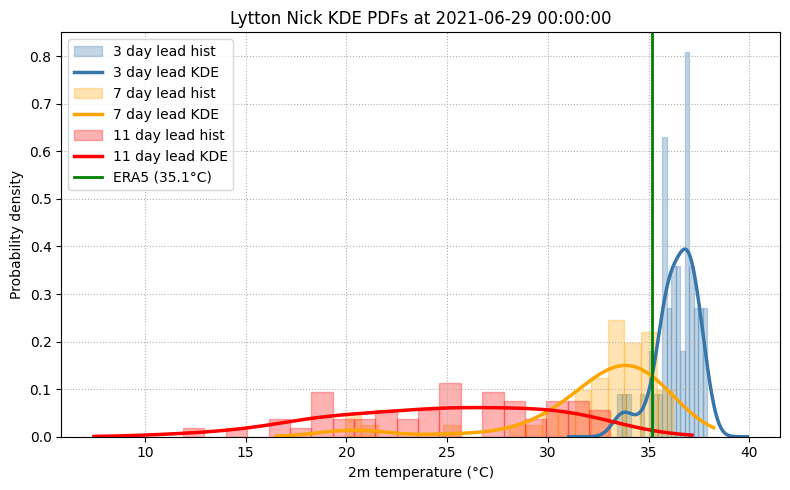

3 day lead
Nick CRPS: 0.8919050423322689
Gencast CRPS: 0.2292187186530427

7 day lead
Nick CRPS: 1.11142073709226
Gencast CRPS: 3.199780993652344

11 day lead
Nick CRPS: 5.280913531577152
Gencast CRPS: 6.968460803222657

11 day lead
Nick CRPS: 5.280913531577152
Gencast CRPS: 6.968460803222657



In [ ]:
# PDFs for 3, 7, 11 day leads
# assumes these already exist in your notebook:
# valid_time, city, city_lat, city_lon, cases
# era5, to_celsius, lon_adjust, combine_seed_ensembles, crps_calculation

# Adjustable histogram settings
hist_alpha = 0.30   # transparency for the histogram bars
hist_bins = 20      # number of histogram bins

colors = ["#3776ab", "#FFA500", "red"]

era5 = xr.open_dataset(
    "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/era5/pnw025/sfc/2021.nc",
    engine="netcdf4"
)
era5 = era5.rename({
    k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
    if k in era5.coords or k in era5.dims
})
era5_truth = to_celsius(era5["t2m"]).sel(time=valid_time, method="nearest")
era5_point = float(np.asarray(lon_adjust(era5_truth, city_lat, city_lon)).squeeze())

results = []

for case in cases:
    # Nick / PNW025
    nick_da = xr.open_dataset(case["nc_path"], engine="netcdf4")
    nick_da = nick_da.rename({
        k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
        if k in nick_da.coords or k in nick_da.dims
    })
    nick_da = to_celsius(nick_da["t2m"])
    nick_city = lon_adjust(nick_da, city_lat, city_lon)

    # GenCast
    gencast_da = combine_seed_ensembles(case["seed_paths"])
    gencast_da = gencast_da.rename({
        k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
        if k in gencast_da.coords or k in gencast_da.dims
    })
    gencast_da = gencast_da.assign_coords(time=pd.to_datetime(case["init_time"]) + gencast_da["time"])
    gencast_da = to_celsius(gencast_da["2m_temperature"])
    gencast_city = lon_adjust(gencast_da, city_lat, city_lon)

    # Extract ensemble values at the valid time
    nick_x = nick_city.sel(time=valid_time, method="nearest").dropna("number").values.astype(float)
    gencast_x = gencast_city.sel(time=valid_time, method="nearest").dropna("number").values.astype(float)

    nick_x = nick_x[np.isfinite(nick_x)]
    gencast_x = gencast_x[np.isfinite(gencast_x)]

    # Sort for CRPS
    nick_x_sorted = np.sort(nick_x)
    gencast_x_sorted = np.sort(gencast_x)

    # KDEs
    nick_kde = gaussian_kde(nick_x)
    gencast_kde = gaussian_kde(gencast_x)

    # Common x-grid for this lead
    all_vals = np.concatenate([nick_x, gencast_x, np.array([era5_point])])
    x_grid = np.linspace(all_vals.min() - 2.0, all_vals.max() + 2.0, 500)

    nick_pdf = nick_kde(x_grid)
    gencast_pdf = gencast_kde(x_grid)

    # CRPS diagnostics
    nick_crps = crps_calculation(nick_x_sorted, era5_point)
    gencast_crps = crps_calculation(gencast_x_sorted, era5_point)

    results.append({
        "label": case["label"],
        "x_grid": x_grid,
        "nick_pdf": nick_pdf,
        "gencast_pdf": gencast_pdf,
        "nick_samples": nick_x,
        "gencast_samples": gencast_x,
        "nick_crps": nick_crps,
        "gencast_crps": gencast_crps,
    })

# Plot GenCast: all three lead times
plt.figure(figsize=(8, 5))

for r, color in zip(results, colors):
    plt.hist(
        r["gencast_samples"],
        bins=hist_bins,
        density=True,
        alpha=hist_alpha,
        color=color,
        edgecolor=color,      # or "black" if you prefer
        label=f'{r["label"]} hist'
    )
    plt.plot(
        r["x_grid"],
        r["gencast_pdf"],
        color=color,
        linewidth=2.5,
        label=f'{r["label"]} KDE'
    )

plt.axvline(era5_point, color="green", linewidth=2, label=f"ERA5 ({era5_point:.1f}°C)")
plt.xlabel("2m temperature (°C)")
plt.ylabel("Probability density")
plt.title(f"{city} GenCast KDE PDFs at {valid_time}")
plt.grid(True, linestyle=":")
plt.legend()
plt.tight_layout()
plt.show()

# Plot Nick: all three lead times
plt.figure(figsize=(8, 5))

for r, color in zip(results, colors):
    plt.hist(
        r["nick_samples"],
        bins=hist_bins,
        density=True,
        alpha=hist_alpha,
        color=color,
        edgecolor=color,
        label=f'{r["label"]} hist'
    )
    plt.plot(
        r["x_grid"],
        r["nick_pdf"],
        color=color,
        linewidth=2.5,
        label=f'{r["label"]} KDE'
    )

plt.axvline(era5_point, color="green", linewidth=2, label=f"ERA5 ({era5_point:.1f}°C)")
plt.xlabel("2m temperature (°C)")
plt.ylabel("Probability density")
plt.title(f"{city} Nick KDE PDFs at {valid_time}")
plt.grid(True, linestyle=":")
plt.legend()
plt.tight_layout()
plt.show()

# Print CRPS diagnostics
for r in results:
    print(r["label"])
    print("IFS CRPS:", r["nick_crps"])
    print("Gencast CRPS:", r["gencast_crps"])
    print()

AND NOW WITH PERTURBED FORECASTS:

/tmp/user/28413/ipykernel_180411/138476893.py:27: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.concat(datasets, dim="sample").sortby("sample")
/tmp/user/28413/ipykernel_180411/138476893.py:27: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.concat(datasets, dim="sample").sortby("sample")
/tmp

GenCast normal: closest = 35.18 °C, truth = 35.15 °C, abs diff = 0.03 °C
GenCast normal: coolest = 33.03 °C
GenCast pi: closest = 35.14 °C, truth = 35.15 °C, abs diff = 0.01 °C
GenCast pi: coolest = 32.84 °C
GenCast incr: closest = 35.15 °C, truth = 35.15 °C, abs diff = 0.00 °C
GenCast incr: coolest = 33.15 °C
Nick normal: closest = 35.32 °C, truth = 35.15 °C, abs diff = 0.17 °C
Nick normal: coolest = 33.71 °C
Nick pi: closest = 35.14 °C, truth = 35.15 °C, abs diff = 0.01 °C
Nick pi: coolest = 33.45 °C
Nick incr: closest = 35.38 °C, truth = 35.15 °C, abs diff = 0.23 °C
Nick incr: coolest = 33.74 °C


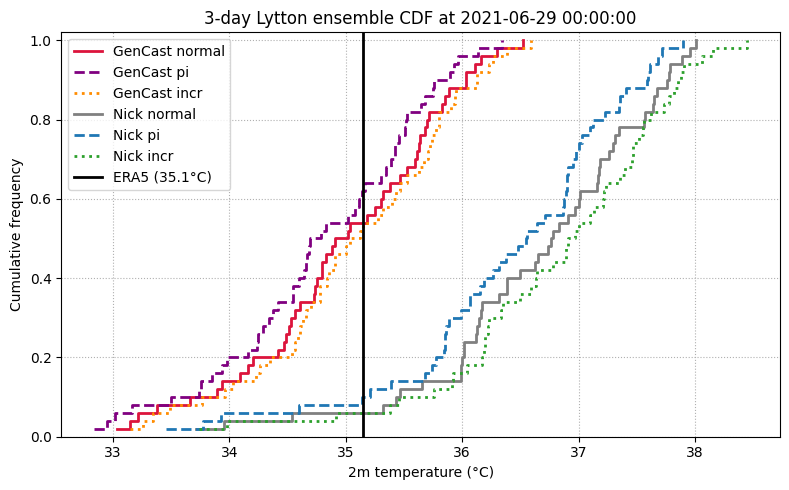

ERA5 truth: 35.15 °C

GenCast normal CRPS: 0.2292187186530427
GenCast normal closest member: (<xarray.DataArray '2m_temperature' ()> Size: 4B
dask.array<getitem, shape=(), dtype=float32, chunksize=(), chunktype=numpy.ndarray>
Coordinates:
    batch      int64 8B 0
    latitude   float32 4B 50.0
    longitude  float32 4B 238.0
    number     int64 8B 27
    time       datetime64[ns] 8B 2021-06-29
Attributes:
    long_name:   2 metre temperature
    short_name:  t2m
    units:       K, <xarray.DataArray '2m_temperature' (number: 50)> Size: 200B
dask.array<absolute, shape=(50,), dtype=float32, chunksize=(13,), chunktype=numpy.ndarray>
Coordinates:
  * number     (number) int64 400B 0 1 2 3 4 5 6 7 8 ... 42 43 44 45 46 47 48 49
    batch      int64 8B 0
    latitude   float32 4B 50.0
    longitude  float32 4B 238.0
    time       datetime64[ns] 8B 2021-06-29
Attributes:
    long_name:   2 metre temperature
    short_name:  t2m
    units:       K)
GenCast normal coolest member: <xarray.Data

In [18]:

gencast_init = pd.Timestamp("2021-06-26T00:00:00")
gencast_init_date = gencast_init.strftime("%Y-%m-%d")

city, city_lat, city_lon = "Lytton", 50.224444, -121.581944
CDF_time = pd.to_datetime("2021-06-29T00:00:00")

era5 = xr.open_dataset(
    "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/era5/pnw025/sfc/2021.nc",
    engine="netcdf4"
)
era5 = era5.rename({k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
                     if k in era5.coords or k in era5.dims})
era5_da = to_celsius(era5["t2m"])
era5_city = lon_adjust(era5_da, city_lat, city_lon)

# -----------------------------
# Nick files
# -----------------------------
nick_paths = {
    "normal": (DATA_ROOT + "/ifs/sfc/oper_pf_2021-06-26.nc"),
    "pi":     "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-26.nc",
    "incr":   "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mh_2021-06-26.nc",
}

# -----------------------------
# GenCast seed-combined files
# Adjust paths if your normal/pi/incr filenames differ.
# -----------------------------
gencast_seed_paths = {
    "normal": [
        (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-26T00_10d/pred_1deg_current_init-2021-06-26T00_10d_seed0_26ens.zarr"),
        (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-26T00_10d/pred_1deg_current_init-2021-06-26T00_10d_seed1_24ens.zarr"),
    ],
    "pi": [
        (DATA_ROOT + "/gencast/predictions/1deg/pi/init-2021-06-26T00_10d/pred_1deg_pi_init-2021-06-26T00_10d_seed0_26ens.zarr"),
        (DATA_ROOT + "/gencast/predictions/1deg/pi/init-2021-06-26T00_10d/pred_1deg_pi_init-2021-06-26T00_10d_seed1_24ens.zarr"),
    ],
    "incr": [
        (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-26T00_10d/pred_1deg_incr_init-2021-06-26T00_10d_seed0_26ens.zarr"),
        (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-26T00_10d/pred_1deg_incr_init-2021-06-26T00_10d_seed1_24ens.zarr"),
    ],
}

# Load Nick
nick = {}
for variant, path in nick_paths.items():
    ds = xr.open_dataset(path, engine="netcdf4")
    ds = ds.rename({k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
                    if k in ds.coords or k in ds.dims})
    nick[variant] = ds

# Load GenCast
gencast = {}
for variant, paths in gencast_seed_paths.items():
    gc = combine_seed_ensembles(paths)
    if "batch" in gc.dims:
        gc = gc.squeeze("batch")
    gc = gc.rename({k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
                     if k in gc.coords or k in gc.dims})
    gencast[variant] = gc

# Build city series
nick_city = {}
for variant in nick:
    nick_da = to_celsius(nick[variant]["t2m"])
    nick_city[variant] = lon_adjust(nick_da, city_lat, city_lon)

gencast_city = {}
for variant in gencast:
    gc_da = to_celsius(gencast[variant]["2m_temperature"]).assign_coords(
        time=pd.to_datetime(gencast_init) + gencast[variant]["time"]
    )
    gencast_city[variant] = lon_adjust(gc_da, city_lat, city_lon)

# Choose the valid time
era5_truth = float(era5_city.sel(time=CDF_time, method="nearest").values)

# Nick normal is commented out by request
#nick_variants_to_use = ["pi", "incr"]
nick_variants_to_use = ["normal", "pi", "incr"]

gencast_variants_to_use = ["normal", "pi", "incr"]

# -----------------------------
# Plot CDFs
# -----------------------------
fig, ax = plt.subplots(figsize=(8, 5))

nick_results = {}
gencast_results = {}

nick_styles = {
    "normal": dict(linestyle="-", color="gray"),
    "pi": dict(linestyle="--", color="tab:blue"),
    "incr": dict(linestyle=":", color="tab:green"),
}

gencast_styles = {
    "normal": dict(linestyle="-", color="crimson"),
    "pi": dict(linestyle="--", color="purple"),
    "incr": dict(linestyle=":", color="darkorange"),
}

for variant in gencast_variants_to_use:
    ens = gencast_city[variant].sel(time=CDF_time, method="nearest").dropna("number").values.astype(float)
    x = np.sort(ens[np.isfinite(ens)])
    y = np.arange(1, len(x) + 1) / len(x)

    gencast_results[variant] = {
        "x": x,
        "y": y,
        "crps": crps_calculation(x, era5_truth),
        "closest": closest_member(gencast_city[variant], era5_truth, CDF_time, ens_dim="number", label=f"GenCast {variant}"),
        "coolest": coolest_member(gencast_city[variant], CDF_time, ens_dim="number", label=f"GenCast {variant}"),
    }

    ax.step(
        x, y, where="post",
        linewidth=2,
        label=f"GenCast {variant}",
        **gencast_styles[variant]
    )

for variant in nick_variants_to_use:
    ens = nick_city[variant].sel(time=CDF_time, method="nearest").dropna("number").values.astype(float)
    x = np.sort(ens[np.isfinite(ens)])
    y = np.arange(1, len(x) + 1) / len(x)

    nick_results[variant] = {
        "x": x,
        "y": y,
        "crps": crps_calculation(x, era5_truth),
        "closest": closest_member(nick_city[variant], era5_truth, CDF_time, ens_dim="number", label=f"Nick {variant}"),
        "coolest": coolest_member(nick_city[variant], CDF_time, ens_dim="number", label=f"Nick {variant}"),
    }

    ax.step(
        x, y, where="post",
        linewidth=2,
        label=f"Nick {variant}",
        **nick_styles[variant]
    )

ax.axvline(
    era5_truth,
    color="black",
    linewidth=2,
    label=f"ERA5 ({era5_truth:.1f}°C)"
)

ax.set_xlabel("2m temperature (°C)")
ax.set_ylabel("Cumulative frequency")
ax.set_title(f"3-day {city} ensemble CDF at {CDF_time}")
ax.set_ylim(0, 1.02)
ax.grid(True, linestyle=":")
ax.legend()
plt.tight_layout()
plt.show()

# -----------------------------
# Print diagnostics
# -----------------------------
print(f"ERA5 truth: {era5_truth:.2f} °C\n")

for variant in gencast_variants_to_use:
    print(f"GenCast {variant} CRPS:", gencast_results[variant]["crps"])
    print("GenCast", variant, "closest member:", gencast_results[variant]["closest"])
    print("GenCast", variant, "coolest member:", gencast_results[variant]["coolest"])
    print()

for variant in nick_variants_to_use:
    print(f"Nick {variant} CRPS:", nick_results[variant]["crps"])
    print("Nick", variant, "closest member:", nick_results[variant]["closest"])
    print("Nick", variant, "coolest member:", nick_results[variant]["coolest"])
    print()

/tmp/user/28413/ipykernel_180411/138476893.py:27: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.concat(datasets, dim="sample").sortby("sample")
/tmp/user/28413/ipykernel_180411/138476893.py:27: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.concat(datasets, dim="sample").sortby("sample")
/tmp

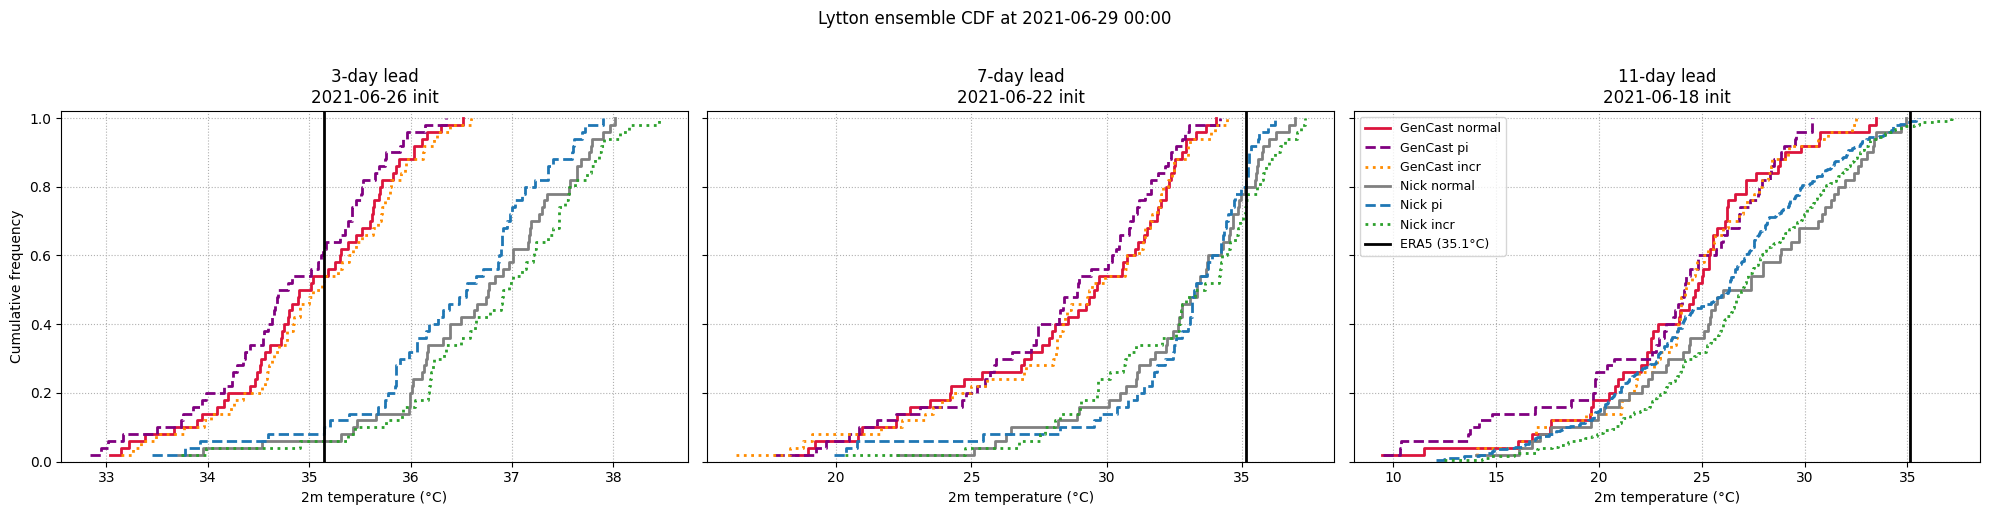

In [19]:
city = "Lytton"
city_lat = 50.224444
city_lon = -121.581944

CDF_time = pd.Timestamp("2021-06-29T00:00:00")


# ============================================================
# ERA5
# ============================================================

era5 = xr.open_dataset(
    "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/"
    "COUNTERFACTUAL-FORECASTING/DATA/era5/pnw025/sfc/2021.nc",
    engine="netcdf4"
)

era5 = era5.rename({
    k: v
    for k, v in {
        "lat": "latitude",
        "lon": "longitude",
        "sample": "number",
    }.items()
    if k in era5.coords or k in era5.dims
})

era5_da = to_celsius(era5["t2m"])
era5_city = lon_adjust(
    era5_da,
    city_lat,
    city_lon
)


# ============================================================
# Forecast cases
# ============================================================

cases = [
    {
        "lead_days": 3,
        "init": pd.Timestamp("2021-06-26T00:00:00"),
        "forecast_steps": 10,
        "nick": {
            "normal": (DATA_ROOT + "/ifs/sfc/oper_pf_2021-06-26.nc"),
            "pi": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-26.nc",
            "incr": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mh_2021-06-26.nc",
        },
        "gencast": {
            "normal": [
                (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-26T00_10d/pred_1deg_current_init-2021-06-26T00_10d_seed0_26ens.zarr"),
                (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-26T00_10d/pred_1deg_current_init-2021-06-26T00_10d_seed1_24ens.zarr"),
            ],
            "pi": [
                (DATA_ROOT + "/gencast/predictions/1deg/pi/init-2021-06-26T00_10d/pred_1deg_pi_init-2021-06-26T00_10d_seed0_26ens.zarr"),
                (DATA_ROOT + "/gencast/predictions/1deg/pi/init-2021-06-26T00_10d/pred_1deg_pi_init-2021-06-26T00_10d_seed1_24ens.zarr"),
            ],
            "incr": [
                (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-26T00_10d/pred_1deg_incr_init-2021-06-26T00_10d_seed0_26ens.zarr"),
                (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-26T00_10d/pred_1deg_incr_init-2021-06-26T00_10d_seed1_24ens.zarr"),
            ],
        },
    },
    {
        "lead_days": 7,
        "init": pd.Timestamp("2021-06-22T00:00:00"),
        "forecast_steps": 18,
        "nick": {
            "normal": (DATA_ROOT + "/ifs/sfc/oper_pf_2021-06-22.nc"),
            "pi": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-22.nc",
            "incr": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mh_2021-06-22.nc",
        },
        "gencast": {
            "normal": [
                (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-22T00_18d/pred_1deg_current_init-2021-06-22T00_18d_seed0_26ens.zarr"),
                (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-22T00_18d/pred_1deg_current_init-2021-06-22T00_18d_seed1_24ens.zarr"),
            ],
            "pi": [
                (DATA_ROOT + "/gencast/predictions/1deg/pi/init-2021-06-22T00_18d/pred_1deg_pi_init-2021-06-22T00_18d_seed0_26ens.zarr"),
                (DATA_ROOT + "/gencast/predictions/1deg/pi/init-2021-06-22T00_18d/pred_1deg_pi_init-2021-06-22T00_18d_seed1_24ens.zarr"),
            ],
            "incr": [
                (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-22T00_18d/pred_1deg_incr_init-2021-06-22T00_18d_seed0_26ens.zarr"),
                (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-22T00_18d/pred_1deg_incr_init-2021-06-22T00_18d_seed1_24ens.zarr"),
            ],
        },
    },
    {
        "lead_days": 11,
        "init": pd.Timestamp("2021-06-18T00:00:00"),
        "forecast_steps": 26,
        "nick": {
            "normal": (DATA_ROOT + "/ifs/sfc/oper_pf_2021-06-18.nc"),
            "pi": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mp_2021-06-18.nc",
            "incr": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mq_2021-06-18.nc",
        },
        "gencast": {
            "normal": [
                (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-18T00_26d/pred_1deg_current_init-2021-06-18T00_26d_seed0_26ens.zarr"),
                (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-18T00_26d/pred_1deg_current_init-2021-06-18T00_26d_seed1_24ens.zarr"),
            ],
            "pi": [
                (DATA_ROOT + "/gencast/predictions/1deg/pi/init-2021-06-18T00_26d/pred_1deg_pi_init-2021-06-18T00_26d_seed0_26ens.zarr"),
                (DATA_ROOT + "/gencast/predictions/1deg/pi/init-2021-06-18T00_26d/pred_1deg_pi_init-2021-06-18T00_26d_seed1_24ens.zarr"),
            ],
            "incr": [
                (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-18T00_26d/pred_1deg_incr_init-2021-06-18T00_26d_seed0_26ens.zarr"),
                (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-18T00_26d/pred_1deg_incr_init-2021-06-18T00_26d_seed1_24ens.zarr"),
            ],
        },
    },
]


# ============================================================
# Styles
# ============================================================

nick_styles = {
    "normal": dict(linestyle="-", color="gray"),
    "pi": dict(linestyle="--", color="tab:blue"),
    "incr": dict(linestyle=":", color="tab:green"),
}

gencast_styles = {
    "normal": dict(linestyle="-", color="crimson"),
    "pi": dict(linestyle="--", color="purple"),
    "incr": dict(linestyle=":", color="darkorange"),
}

nick_variants = ["normal", "pi", "incr"]
gencast_variants = ["normal", "pi", "incr"]


# ============================================================
# Load one Nick forecast
# ============================================================

def load_nick_city_series(path):
    ds = xr.open_dataset(path, engine="netcdf4")

    ds = ds.rename({
        k: v
        for k, v in {
            "lat": "latitude",
            "lon": "longitude",
            "sample": "number",
        }.items()
        if k in ds.coords or k in ds.dims
    })

    da = to_celsius(ds["t2m"])

    return lon_adjust(
        da,
        city_lat,
        city_lon
    )


# ============================================================
# Load and combine one GenCast variant
# ============================================================

def load_gencast_city_series(paths, init_date):

    gc = combine_seed_ensembles(paths)

    if "batch" in gc.dims:
        gc = gc.squeeze("batch")

    gc = gc.rename({
        k: v
        for k, v in {
            "lat": "latitude",
            "lon": "longitude",
            "sample": "number",
        }.items()
        if k in gc.coords or k in gc.dims
    })

    da = to_celsius(gc["2m_temperature"])

    da = da.assign_coords(
        time=pd.to_datetime(init_date) + da["time"]
    )

    return lon_adjust(
        da,
        city_lat,
        city_lon
    )


# ============================================================
# Plot
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(20, 5),
    sharey=True
)

for ax, case in zip(axes, cases):

    init_date = case["init"]

    # -------------------------
    # Load forecasts
    # -------------------------

    nick_city = {
        variant: load_nick_city_series(path)
        for variant, path in case["nick"].items()
    }

    gencast_city = {
        variant: load_gencast_city_series(paths, init_date)
        for variant, paths in case["gencast"].items()
    }

    # -------------------------
    # ERA5 truth
    # -------------------------

    era5_truth = float(
        era5_city.sel(
            time=CDF_time,
            method="nearest"
        ).values
    )

    # -------------------------
    # GenCast CDFs
    # -------------------------

    for variant in gencast_variants:

        ens = (
            gencast_city[variant]
            .sel(time=CDF_time, method="nearest")
            .dropna("number")
            .values
            .astype(float)
        )

        ens = ens[np.isfinite(ens)]

        x = np.sort(ens)
        y = np.arange(1, len(x) + 1) / len(x)

        ax.step(
            x,
            y,
            where="post",
            linewidth=2,
            label=f"GenCast {variant}",
            **gencast_styles[variant]
        )

    # -------------------------
    # Nick CDFs
    # -------------------------

    for variant in nick_variants:

        ens = (
            nick_city[variant]
            .sel(time=CDF_time, method="nearest")
            .dropna("number")
            .values
            .astype(float)
        )

        ens = ens[np.isfinite(ens)]

        x = np.sort(ens)
        y = np.arange(1, len(x) + 1) / len(x)

        ax.step(
            x,
            y,
            where="post",
            linewidth=2,
            label=f"Nick {variant}",
            **nick_styles[variant]
        )

    # -------------------------
    # ERA5
    # -------------------------

    ax.axvline(
        era5_truth,
        color="black",
        linewidth=2,
        label=f"ERA5 ({era5_truth:.1f}°C)"
    )

    ax.set_title(
        f"{case['lead_days']}-day lead\n"
        f"{init_date.strftime('%Y-%m-%d')} init"
    )

    ax.set_xlabel("2m temperature (°C)")
    ax.set_ylim(0, 1.02)
    ax.grid(True, linestyle=":")

axes[0].set_ylabel("Cumulative frequency")
axes[-1].legend(loc="best", fontsize=9)

fig.suptitle(
    f"{city} ensemble CDF at {CDF_time.strftime('%Y-%m-%d %H:%M')}",
    y=1.02
)

plt.tight_layout()
plt.show()

9.58698085454085 0.05848323761382401


/tmp/user/28413/ipykernel_2308755/138476893.py:27: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.concat(datasets, dim="sample").sortby("sample")


5.008493900299072 0.0460939227732706


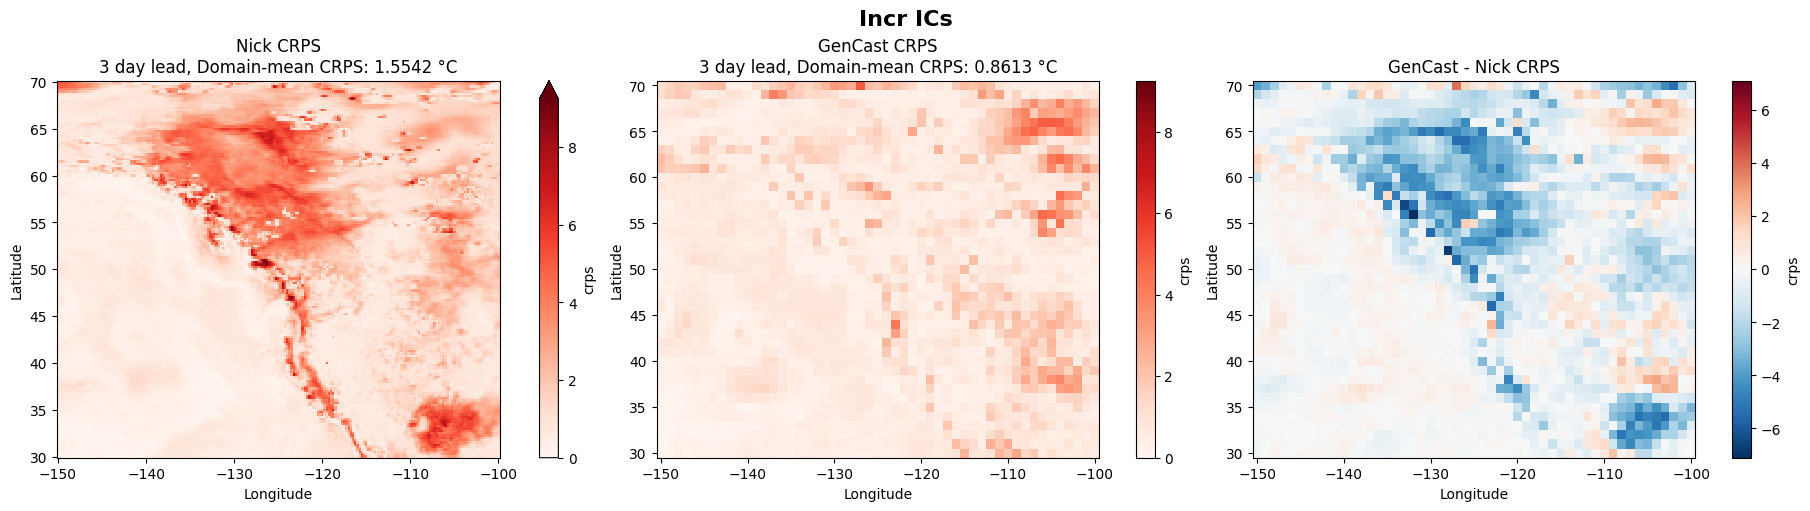

Domain-mean CRPS
Nick:    1.5542 °C
GenCast: 0.8613 °C


In [ ]:
valid_time = pd.Timestamp("2021-06-29T00:00:00")
LAT_RANGE = (30, 70)
LON_RANGE = (-150, -100)

cases = [
    {
        "label": "3 day lead",
        "init_time": pd.Timestamp("2021-06-26T00:00:00"),
        "nc_path": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mh_2021-06-22.nc",#/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/control/oper_pf_2021-06-26.nc",
        "seed_paths": [
            (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-26T00_10d/pred_1deg_incr_init-2021-06-26T00_10d_seed0_26ens.zarr"),
            (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-26T00_10d/pred_1deg_incr_init-2021-06-26T00_10d_seed1_24ens.zarr"),
        ],
    },
    {
        "label": "7 day lead",
        "init_time": pd.Timestamp("2021-06-22T00:00:00"),
        "nc_path": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-22.nc",
        "seed_paths": [
            (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-22T00_18d/pred_1deg_current_init-2021-06-22T00_18d_seed0_26ens.zarr"),
            (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-22T00_18d/pred_1deg_current_init-2021-06-22T00_18d_seed1_24ens.zarr"),
        ],
    },
    {
        "label": "11 day lead",
        "init_time": pd.Timestamp("2021-06-18T00:00:00"),
        "nc_path": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-18.nc",
        "seed_paths": [
            (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-18T00_26d/pred_1deg_current_init-2021-06-18T00_26d_seed0_26ens.zarr"),
            (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-18T00_26d/pred_1deg_current_init-2021-06-18T00_26d_seed1_24ens.zarr"),
        ],
    },
    {
        "label": "11 day lead",
        "init_time": pd.Timestamp("2021-06-18T00:00:00"),
        "nc_path": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-18.nc",
        "seed_paths": [
            (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-18T00_26d/pred_1deg_current_init-2021-06-18T00_26d_seed0_26ens.zarr"),
            (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-18T00_26d/pred_1deg_current_init-2021-06-18T00_26d_seed1_24ens.zarr"),
        ],
    },
]

case = cases[0]  # change the lead time

era5 = xr.open_dataset(
    "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/era5/pnw025/sfc/2021.nc",
    engine="netcdf4")
era5 = era5.rename({k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
                      if k in era5.coords or k in era5.dims})
era5_truth = to_celsius(era5["t2m"]).sel(time=valid_time, method="nearest")

nick_da = xr.open_dataset(case["nc_path"], engine="netcdf4")
nick_da = nick_da.rename({k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
                      if k in nick_da.coords or k in nick_da.dims})
nick_da = to_celsius(nick_da["t2m"])
nick_fcst = nick_da.sel(time=valid_time)
nick_crps = crps_map_pointwise(nick_fcst, era5_truth)

gencast_da = combine_seed_ensembles(case["seed_paths"])
gencast_da = gencast_da.rename({k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
                      if k in gencast_da.coords or k in gencast_da.dims})
gencast_da = gencast_da.assign_coords(time=pd.to_datetime(gencast_init) + gencast_da["time"])
gencast_fcst = gencast_da["2m_temperature"].sel(time=valid_time)
gencast_fcst = to_celsius(gencast_fcst)
gencast_crps = crps_map_pointwise(gencast_fcst, era5_truth)

vmax = 9.244239252245213#max(float(gencast_crps.max()), float(nick_crps.max()))

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)

nick_crps.plot(ax=axes[0], cmap="Reds", vmin=0, vmax=vmax, add_colorbar=True)
axes[0].set_title(f"Nick CRPS\n{case['label']}, Domain-mean CRPS: {float(nick_crps.mean()):.4f} °C")

gencast_crps.plot(ax=axes[1], cmap="Reds", vmin=0, vmax=vmax, add_colorbar=True)
axes[1].set_title(f"GenCast CRPS\n{case['label']}, Domain-mean CRPS: {float(gencast_crps.mean()):.4f} °C")

(gencast_crps - nick_crps).plot(ax=axes[2], cmap="RdBu_r", center=0, add_colorbar=True)
axes[2].set_title("GenCast - Nick CRPS")

for ax in axes:
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
#    ax.set_xlim(-123, -119)
#    ax.set_ylim(45,52)

fig.suptitle(f"Incr ICs", 
             fontsize=16, fontweight='bold')
plt.show()

print("Domain-mean CRPS")
print(f"Nick:    {float(nick_crps.mean()):.4f} °C")
print(f"GenCast: {float(gencast_crps.mean()):.4f} °C")